# CSE 475
## Assignment 01
## Group Information

| Field | Details |
| :--- | :--- |
| **Group ID** | Group C |
| **Student 1 Name** | S.K Jihad Mahmud |
| **Student 1 ID** | 2022-1-60-061 |
| **Student 2 Name** | Nasrullah Kaisher Sijan |
| **Student 2 ID** | 2023-1-60-204 |
| **Notebook Type** | CNN Models (MobileNetV3, ResNeXt-50, EfficientNet-B3) |
| **Dataset Source Name** | Tropical Flower Dataset |
| **Dataset Source Link** | https://data.mendeley.com/datasets/njfg9nh92t/1 |
| **Kaggle Dataset Path** |/kaggle/input/datasets/skjihadmahmud/cse475-groupc-dataset-cnn/Flower Dataset|
| **Submission Date** | 31 March 2026 |

# 1. Global Configuration

In [1]:

  
   # =========================
# 1. Global Configuration
# =========================

import os
from pathlib import Path

CFG = {
    # -------------------------
    # Reproducibility
    # -------------------------
    "seed": 42,

    # -------------------------
    # Dataset Path (UPDATED)
    # -------------------------
    "raw_data_dir": "/kaggle/input/datasets/skjihadmahmud/cse475-groupc-dataset-cnn/Flower Dataset",

    # -------------------------
    # Working Directories
    # -------------------------
    "work_dir": "/kaggle/working/flower_pipeline",
    "split_dir": "/kaggle/working/flower_pipeline/splits",
    "train_dir": "/kaggle/working/flower_pipeline/splits/train",
    "val_dir": "/kaggle/working/flower_pipeline/splits/val",
    "test_dir": "/kaggle/working/flower_pipeline/splits/test",

    "checkpoints_dir": "/kaggle/working/flower_pipeline/checkpoints",
    "plots_dir": "/kaggle/working/flower_pipeline/plots",
    "results_dir": "/kaggle/working/flower_pipeline/results",

    # -------------------------
    # Image Processing
    # -------------------------
    "img_size": 224,              # Good for pretrained CNNs
    "resize_margin": 32,
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],

    # -------------------------
    # Dataset Split
    # -------------------------
    "train_ratio": 0.80,
    "val_ratio": 0.10,
    "test_ratio": 0.10,

    # -------------------------
    # EDA Settings
    # -------------------------
    "eda_samples_per_class": 3,
    "eda_stats_max_images_per_class": None,

    # -------------------------
    # DataLoader
    # -------------------------
    "batch_size": 32,         # Change to 16 if GPU is small
    "num_workers": 2,

    # -------------------------
    # Training Settings
    # -------------------------
    "epochs": 30,             # Increased for better performance
    "patience": 8,

    "optimizer_name": "adamw",   # "adamw" or "sgd"
    "lr": 1e-4,
    "momentum": 0.9,
    "weight_decay": 1e-4,

    "scheduler_name": "plateau", # "plateau" or "cosine"
    "scheduler_factor": 0.5,
    "scheduler_tmax": 20,
    "scheduler_min_lr": 1e-6,

    "label_smoothing": 0.0,
    "grad_clip_norm": 1.0,

    # -------------------------
    # Data Augmentation
    # -------------------------
    "random_flip_p": 0.5,
    "random_rotation_deg": 15,  # Slightly higher for flowers
    "random_resized_crop_scale": (0.8, 1.0),

    "randaugment_num_ops": 2,
    "randaugment_magnitude": 9,

    # Advanced Augmentation
    "use_mixup": True,
    "use_cutmix": True,
    "mixup_alpha": 0.2,
    "cutmix_alpha": 1.0,

    # -------------------------
    # Evaluation
    # -------------------------
    "top_k_errors": 12,
    "plot_dpi": 140,

    # -------------------------
    # Robustness Analysis
    # -------------------------
    "robust_noise_stds": [0.0, 0.03, 0.06, 0.10, 0.15],
    "robust_brightness_levels": [1.0, 0.9, 0.8, 0.7, 0.6],
    "robust_contrast_levels": [1.0, 0.9, 0.8, 0.7, 0.6],

    # -------------------------
    # Models to Train
    # -------------------------
    "model_order": [
        "mobilenetv3_large",
        "resnext50_32x4d",
        "efficientnet_b3"
    ],
}

# -------------------------
# Create Directories
# -------------------------
for p in [
    CFG["work_dir"],
    CFG["split_dir"],
    CFG["checkpoints_dir"],
    CFG["plots_dir"],
    CFG["results_dir"]
]:
    os.makedirs(p, exist_ok=True)

print("✅ Global configuration loaded successfully!")

✅ Global configuration loaded successfully!


# 2. Setup & Imports

In [2]:
import random
import time
import math
import json
import copy
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import functional as TF

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG["device"] = str(device)
CFG["pin_memory"] = torch.cuda.is_available()

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything(CFG["seed"])

print("Device:", device)
print("torch:", torch.__version__)
print("torchvision:", models.__version__ if hasattr(models, "__version__") else "N/A")
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
torch: 2.10.0+cu128
torchvision: N/A
cuda available: True
GPU: Tesla T4


# 3. Exploratory Data Analysis (EDA)

Classes found: ['Bougainvillea', 'Crown of thorns', 'Hibiscus', 'Jungle geranium', 'Madagascar periwinkle', 'Marigold', 'Rose']


,class,count
0,Rose,827
1,Marigold,717
2,Jungle geranium,698
3,Crown of thorns,583
4,Bougainvillea,580
5,Hibiscus,548
6,Madagascar periwinkle,366


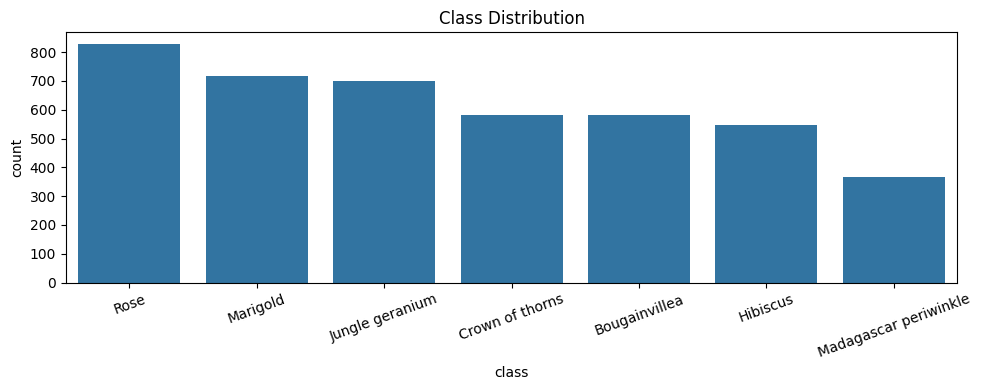

Imbalance ratio (max/min): 2.26
Corrupt files detected in quick check: 0


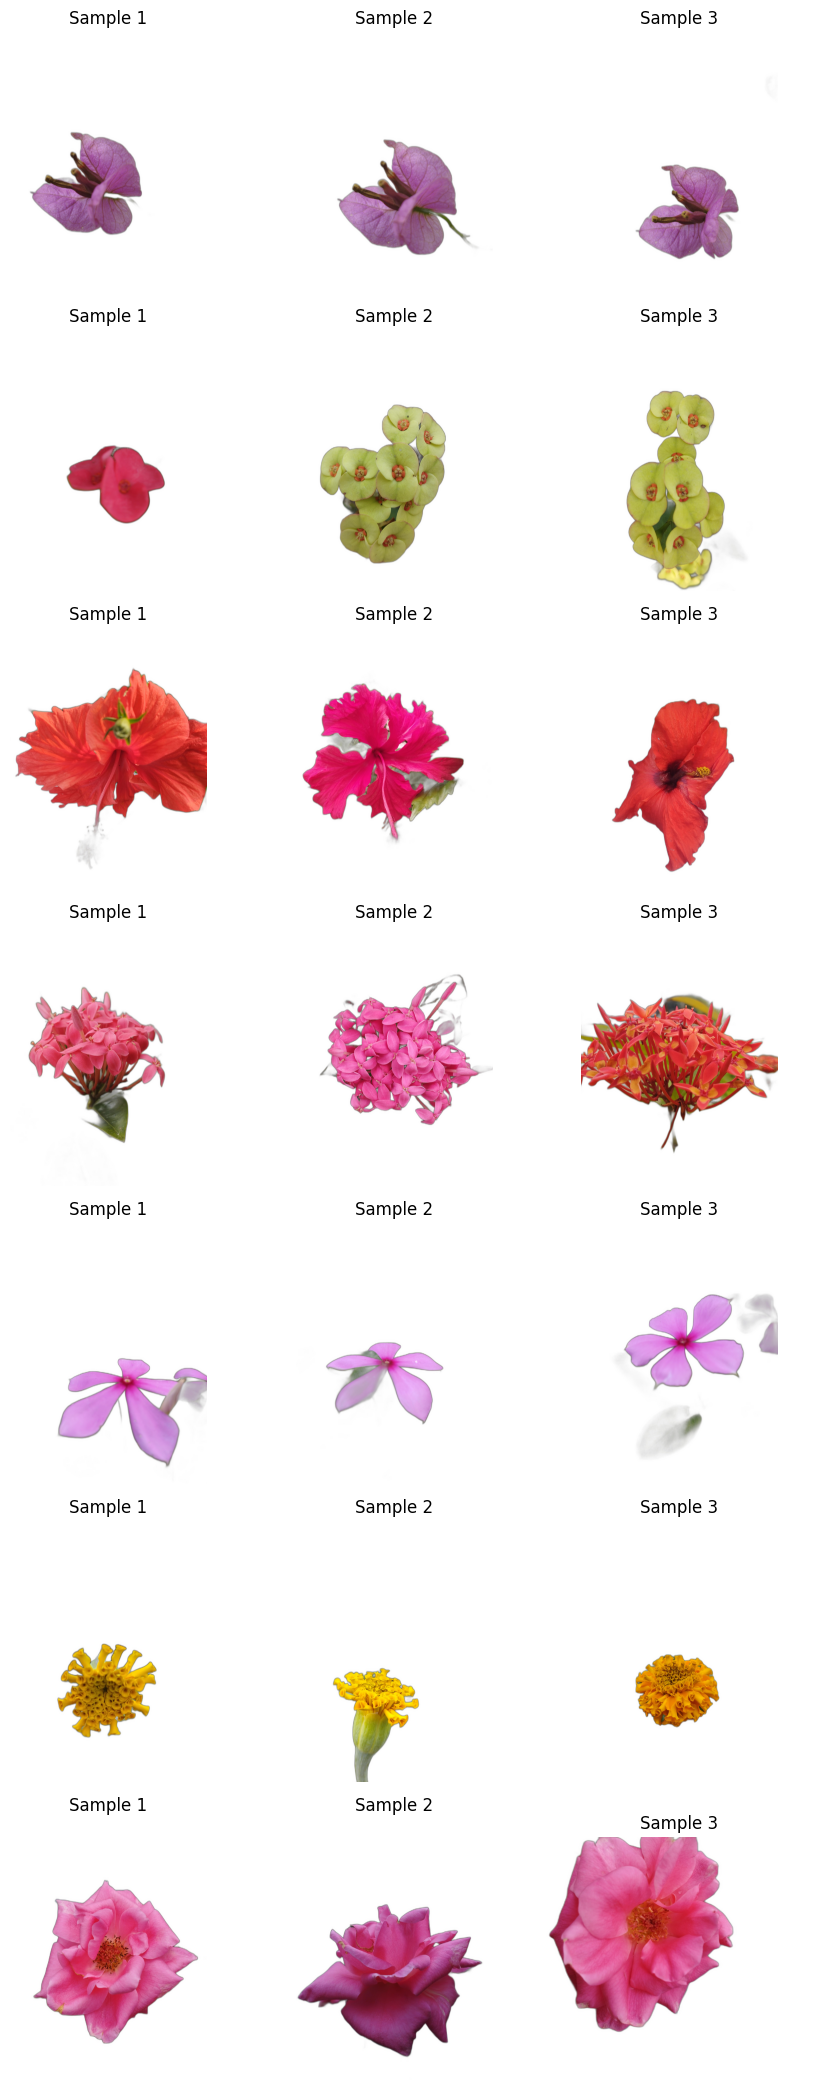

,class,width,height,path
0,Bougainvillea,3072,4080,/kaggle/input/datasets/skjihadmahmud/cse475-gr...
1,Bougainvillea,3072,4080,/kaggle/input/datasets/skjihadmahmud/cse475-gr...
2,Bougainvillea,3072,4080,/kaggle/input/datasets/skjihadmahmud/cse475-gr...
3,Bougainvillea,3072,4080,/kaggle/input/datasets/skjihadmahmud/cse475-gr...
4,Bougainvillea,3072,4080,/kaggle/input/datasets/skjihadmahmud/cse475-gr...


Width  - min: 2448 max: 4080 mean: 3127.15
Height - min: 2448 max: 4080 mean: 4020.37
Most common image modes: [('RGB', 4319)]


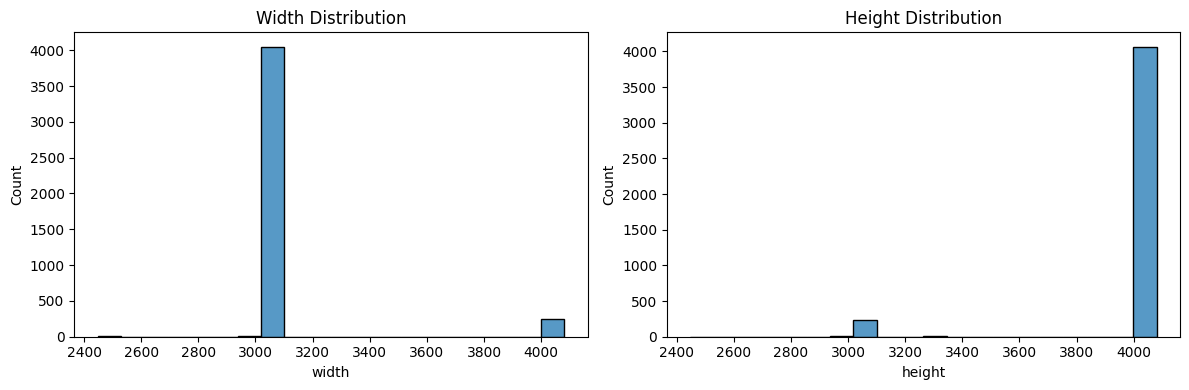

EDA note:
- If the size distribution is wide, resizing/cropping is necessary.
- If grayscale images dominate, RGB conversion is required for ImageNet pretrained backbones.


In [3]:
raw_root = Path(CFG["raw_data_dir"])
if not raw_root.exists():
    raise FileNotFoundError(f"Raw data directory not found: {raw_root}")

class_dirs = sorted([p for p in raw_root.iterdir() if p.is_dir()])
class_names_raw = [p.name for p in class_dirs]
print("Classes found:", class_names_raw)

# Count images per class
counts = []
sample_paths = {}
corrupt_files = []

for cls_dir in class_dirs:
    files = sorted([
        p for p in cls_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]
    ])
    counts.append({"class": cls_dir.name, "count": len(files)})
    sample_paths[cls_dir.name] = files[:CFG["eda_samples_per_class"]]

    # quick corruption check
    for fp in files[: min(len(files), 200)]:  # cap to keep EDA fast
        try:
            Image.open(fp).verify()
        except Exception:
            corrupt_files.append(str(fp))

df_counts = pd.DataFrame(counts).sort_values("count", ascending=False).reset_index(drop=True)
display(df_counts)

plt.figure(figsize=(10, 4))
sns.barplot(data=df_counts, x="class", y="count")
plt.title("Class Distribution")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(Path(CFG["plots_dir"]) / "eda_class_distribution.png", dpi=CFG["plot_dpi"])
plt.show()

# Imbalance check
if len(df_counts) > 1:
    imbalance_ratio = df_counts["count"].max() / max(df_counts["count"].min(), 1)
    print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")
else:
    print("Only one class found.")

print(f"Corrupt files detected in quick check: {len(corrupt_files)}")
if corrupt_files:
    print("Example corrupt file:", corrupt_files[0])

# Sample images per class
n_classes = len(class_names_raw)
n_show = CFG["eda_samples_per_class"]
fig, axes = plt.subplots(n_classes, n_show, figsize=(3 * n_show, 3 * n_classes))
if n_classes == 1:
    axes = np.array([axes])

for i, cls in enumerate(class_names_raw):
    for j in range(n_show):
        ax = axes[i, j] if n_show > 1 else axes[i]
        ax.axis("off")
        if j < len(sample_paths[cls]):
            img = Image.open(sample_paths[cls][j]).convert("RGB")
            ax.imshow(img)
            if j == 0:
                ax.set_ylabel(cls, fontsize=10)
            ax.set_title(f"Sample {j+1}")
plt.tight_layout()
plt.savefig(Path(CFG["plots_dir"]) / "eda_sample_images.png", dpi=CFG["plot_dpi"])
plt.show()

# Image size statistics
size_rows = []
mode_counter = Counter()

for cls_dir in class_dirs:
    files = sorted([
        p for p in cls_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]
    ])
    if CFG["eda_stats_max_images_per_class"] is not None:
        files = files[:CFG["eda_stats_max_images_per_class"]]

    for fp in files:
        try:
            img = Image.open(fp)
            w, h = img.size
            mode_counter[img.mode] += 1
            size_rows.append({"class": cls_dir.name, "width": w, "height": h, "path": str(fp)})
        except Exception:
            pass

size_df = pd.DataFrame(size_rows)
display(size_df.head())

if not size_df.empty:
    print("Width  - min:", size_df["width"].min(), "max:", size_df["width"].max(), "mean:", round(size_df["width"].mean(), 2))
    print("Height - min:", size_df["height"].min(), "max:", size_df["height"].max(), "mean:", round(size_df["height"].mean(), 2))
    print("Most common image modes:", mode_counter.most_common(5))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(size_df["width"], bins=20, ax=axes[0])
    axes[0].set_title("Width Distribution")
    sns.histplot(size_df["height"], bins=20, ax=axes[1])
    axes[1].set_title("Height Distribution")
    plt.tight_layout()
    plt.savefig(Path(CFG["plots_dir"]) / "eda_image_size_histograms.png", dpi=CFG["plot_dpi"])
    plt.show()

    print("EDA note:")
    print("- If the size distribution is wide, resizing/cropping is necessary.")
    print("- If grayscale images dominate, RGB conversion is required for ImageNet pretrained backbones.")

# 4. Data Preprocessing & Augmentation

In [4]:
import shutil

def prepare_split_folders(raw_dir, split_dir, train_ratio, val_ratio, test_ratio, seed):
    raw_dir = Path(raw_dir)
    split_dir = Path(split_dir)
    train_dir = split_dir / "train"
    val_dir = split_dir / "val"
    test_dir = split_dir / "test"

    # Skip if already prepared
    if train_dir.exists() and any(train_dir.rglob("*.*")):
        print("Split folders already exist. Skipping split creation.")
        return str(train_dir), str(val_dir), str(test_dir)

    rng = random.Random(seed)

    class_dirs = sorted([p for p in raw_dir.iterdir() if p.is_dir()])
    for cls_dir in class_dirs:
        files = sorted([
            p for p in cls_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]
        ])
        rng.shuffle(files)

        n_total = len(files)
        n_train = int(n_total * train_ratio)
        n_val = int(n_total * val_ratio)
        n_test = n_total - n_train - n_val

        split_map = {
            train_dir: files[:n_train],
            val_dir: files[n_train:n_train + n_val],
            test_dir: files[n_train + n_val:]
        }

        for target_root, target_files in split_map.items():
            target_cls = target_root / cls_dir.name
            target_cls.mkdir(parents=True, exist_ok=True)
            for fp in target_files:
                shutil.copy2(fp, target_cls / fp.name)

    print("Split folders created.")
    return str(train_dir), str(val_dir), str(test_dir)

CFG["train_dir"], CFG["val_dir"], CFG["test_dir"] = prepare_split_folders(
    CFG["raw_data_dir"],
    CFG["split_dir"],
    CFG["train_ratio"],
    CFG["val_ratio"],
    CFG["test_ratio"],
    CFG["seed"]
)

randaugment = transforms.RandAugment(
    num_ops=CFG["randaugment_num_ops"],
    magnitude=CFG["randaugment_magnitude"]
) if hasattr(transforms, "RandAugment") else transforms.RandomRotation(CFG["random_rotation_deg"])

train_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((CFG["img_size"] + CFG["resize_margin"], CFG["img_size"] + CFG["resize_margin"])),
    transforms.RandomResizedCrop(CFG["img_size"], scale=CFG["random_resized_crop_scale"]),
    transforms.RandomHorizontalFlip(p=CFG["random_flip_p"]),
    transforms.RandomRotation(CFG["random_rotation_deg"]),
    randaugment,
    transforms.ToTensor(),
    transforms.Normalize(mean=CFG["imagenet_mean"], std=CFG["imagenet_std"]),
])

eval_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((CFG["img_size"] + CFG["resize_margin"], CFG["img_size"] + CFG["resize_margin"])),
    transforms.CenterCrop(CFG["img_size"]),
    transforms.ToTensor(),
    transforms.Normalize(mean=CFG["imagenet_mean"], std=CFG["imagenet_std"]),
])

train_dataset = datasets.ImageFolder(CFG["train_dir"], transform=train_tfms)
val_dataset   = datasets.ImageFolder(CFG["val_dir"], transform=eval_tfms)
test_dataset  = datasets.ImageFolder(CFG["test_dir"], transform=eval_tfms)

train_loader = DataLoader(
    train_dataset,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=CFG["num_workers"],
    pin_memory=CFG["pin_memory"]
)
val_loader = DataLoader(
    val_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=CFG["pin_memory"]
)
test_loader = DataLoader(
    test_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=CFG["pin_memory"]
)

CLASS_NAMES = train_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print("Class names:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

Split folders created.
Class names: ['Bougainvillea', 'Crown of thorns', 'Hibiscus', 'Jungle geranium', 'Madagascar periwinkle', 'Marigold', 'Rose']
Number of classes: 7


# 5.Training Infrastructure

In [5]:
def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build_optimizer(model):
    params = [p for p in model.parameters() if p.requires_grad]
    name = CFG["optimizer_name"].lower()

    if name == "sgd":
        return torch.optim.SGD(
            params,
            lr=CFG["lr"],
            momentum=CFG["momentum"],
            weight_decay=CFG["weight_decay"],
            nesterov=True
        )
    elif name == "adam":
        return torch.optim.Adam(
            params,
            lr=CFG["lr"],
            weight_decay=CFG["weight_decay"]
        )
    else:
        return torch.optim.AdamW(
            params,
            lr=CFG["lr"],
            weight_decay=CFG["weight_decay"]
        )

def build_scheduler(optimizer):
    name = CFG["scheduler_name"].lower()
    if name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=CFG["scheduler_tmax"],
            eta_min=CFG["scheduler_min_lr"]
        )
    elif name == "plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=CFG["scheduler_factor"],
            patience=2
        )
    return None

def softmax_probs(logits):
    return torch.softmax(logits, dim=1)

def mixup_data(x, y, alpha):
    if alpha <= 0:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def rand_bbox(size, lam):
    # size = [B, C, H, W]
    W = size[3]
    H = size[2]
    cut_rat = math.sqrt(1.0 - lam)
    cut_w = int(W * cut_rat)
    cut_h = int(H * cut_rat)

    cx = np.random.randint(W)
    cy = np.random.randint(H)

    bbx1 = np.clip(cx - cut_w // 2, 0, W)
    bby1 = np.clip(cy - cut_h // 2, 0, H)
    bbx2 = np.clip(cx + cut_w // 2, 0, W)
    bby2 = np.clip(cy + cut_h // 2, 0, H)

    return bbx1, bby1, bbx2, bby2

def cutmix_data(x, y, alpha):
    if alpha <= 0:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)

    bbx1, bby1, bbx2, bby2 = rand_bbox(x.size(), lam)
    x_mixed = x.clone()
    x_mixed[:, :, bby1:bby2, bbx1:bbx2] = x[index, :, bby1:bby2, bbx1:bbx2]

    # adjust lambda based on actual area
    area = (bbx2 - bbx1) * (bby2 - bby1)
    lam = 1 - area / (x.size(-1) * x.size(-2))

    y_a, y_b = y, y[index]
    return x_mixed, y_a, y_b, lam

class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = float("inf")
        self.counter = 0
        self.should_stop = False

    def step(self, value):
        if value < self.best - self.min_delta:
            self.best = value
            self.counter = 0
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.should_stop = True
        return False

def plot_history(history, model_name):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train Loss")
    axes[0].plot(epochs, history["val_loss"], label="Val Loss")
    axes[0].set_title(f"{model_name} Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train Acc")
    axes[1].plot(epochs, history["val_acc"], label="Val Acc")
    axes[1].set_title(f"{model_name} Accuracy")
    axes[1].legend()

    plt.tight_layout()
    out = Path(CFG["plots_dir"]) / f"{model_name}_curves.png"
    plt.savefig(out, dpi=CFG["plot_dpi"])
    plt.show()

def save_checkpoint(path, model, optimizer, scheduler, epoch, best_val_loss, class_names, history, model_name):
    ckpt = {
        "model_name": model_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict() if optimizer is not None else None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "best_val_loss": best_val_loss,
        "class_names": class_names,
        "cfg": CFG,
        "history": history
    }
    torch.save(ckpt, path)

def load_checkpoint(path, model):
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    return ckpt

@torch.no_grad()
def evaluate_loader(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    y_true, y_pred, y_prob = [], [], []
    start = time.perf_counter()

    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        out = model(xb)
        if isinstance(out, (tuple, list)):
            out = out[0]

        if criterion is not None:
            loss = criterion(out, yb)
            total_loss += loss.item() * xb.size(0)

        probs = torch.softmax(out, dim=1)
        preds = torch.argmax(probs, dim=1)

        total_correct += (preds == yb).sum().item()
        total_samples += yb.size(0)

        y_true.extend(yb.detach().cpu().numpy().tolist())
        y_pred.extend(preds.detach().cpu().numpy().tolist())
        y_prob.extend(probs.detach().cpu().numpy().tolist())

    elapsed = time.perf_counter() - start
    ms_per_batch = (elapsed / max(len(loader), 1)) * 1000.0

    avg_loss = total_loss / max(total_samples, 1) if criterion is not None else None
    acc = total_correct / max(total_samples, 1)

    return {
        "loss": avg_loss,
        "acc": acc,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred),
        "y_prob": np.array(y_prob),
        "ms_per_batch": ms_per_batch
    }

def train_one_model(model, model_name, train_loader, val_loader):
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
    optimizer = build_optimizer(model)
    scheduler = build_scheduler(optimizer)
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    early_stopper = EarlyStopping(patience=CFG["patience"], min_delta=1e-4)

    best_path = str(Path(CFG["checkpoints_dir"]) / f"{model_name}_best.pt")
    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "lr": []
    }

    best_val_loss = float("inf")

    for epoch in range(1, CFG["epochs"] + 1):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            use_mixup = CFG["use_mixup"] and (np.random.rand() < 0.5)
            use_cutmix = CFG["use_cutmix"] and (not use_mixup)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                if use_mixup:
                    xm, ya, yb2, lam = mixup_data(xb, yb, CFG["mixup_alpha"])
                    out = model(xm)
                    if isinstance(out, (tuple, list)):
                        out = out[0]
                    loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb2)
                    preds = out.argmax(dim=1)
                elif use_cutmix:
                    xm, ya, yb2, lam = cutmix_data(xb, yb, CFG["cutmix_alpha"])
                    out = model(xm)
                    if isinstance(out, (tuple, list)):
                        out = out[0]
                    loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb2)
                    preds = out.argmax(dim=1)
                else:
                    out = model(xb)
                    if isinstance(out, (tuple, list)):
                        out = out[0]
                    loss = criterion(out, yb)
                    preds = out.argmax(dim=1)

            scaler.scale(loss).backward()
            if CFG["grad_clip_norm"] is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip_norm"])
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * xb.size(0)
            running_correct += (preds == yb).sum().item()
            running_total += yb.size(0)

        train_loss = running_loss / running_total
        train_acc = running_correct / running_total

        val_stats = evaluate_loader(model, val_loader, criterion=criterion)
        val_loss = val_stats["loss"]
        val_acc = val_stats["acc"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if scheduler is not None:
            if CFG["scheduler_name"].lower() == "plateau":
                scheduler.step(val_loss)
            else:
                scheduler.step()

        improved = val_loss < best_val_loss - 1e-4
        if improved:
            best_val_loss = val_loss
            save_checkpoint(best_path, model, optimizer, scheduler, epoch, best_val_loss, CLASS_NAMES, history, model_name)

        print(
            f"[{model_name}] Epoch {epoch:02d}/{CFG['epochs']} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
            f"best_val_loss={best_val_loss:.4f}"
        )

        early_stopper.step(val_loss)
        if early_stopper.should_stop:
            print(f"[{model_name}] Early stopping triggered.")
            break

    # load best checkpoint before returning
    ckpt = torch.load(best_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    history = ckpt["history"]
    return model, history, best_path

# 6. CNN Models: MobileNetV3 · ResNeXt-50 · EfficientNet-B3


Training: mobilenetv3_large
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 125MB/s] 


Trainable params: 4,210,999


/tmp/ipykernel_25/3789142405.py:202: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_25/3789142405.py:229: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


[mobilenetv3_large] Epoch 01/30 | train_loss=1.0934 train_acc=0.5133 | val_loss=0.2400 val_acc=0.9486 | best_val_loss=0.2400
[mobilenetv3_large] Epoch 02/30 | train_loss=0.7914 train_acc=0.5773 | val_loss=0.2056 val_acc=0.9720 | best_val_loss=0.2056
[mobilenetv3_large] Epoch 03/30 | train_loss=0.7182 train_acc=0.6188 | val_loss=0.1578 val_acc=0.9860 | best_val_loss=0.1578
[mobilenetv3_large] Epoch 04/30 | train_loss=0.7057 train_acc=0.6159 | val_loss=0.2163 val_acc=0.9836 | best_val_loss=0.1578
[mobilenetv3_large] Epoch 05/30 | train_loss=0.6309 train_acc=0.6052 | val_loss=0.0975 val_acc=0.9860 | best_val_loss=0.0975
[mobilenetv3_large] Epoch 06/30 | train_loss=0.6145 train_acc=0.6330 | val_loss=0.0902 val_acc=0.9860 | best_val_loss=0.0902
[mobilenetv3_large] Epoch 07/30 | train_loss=0.6742 train_acc=0.6315 | val_loss=0.1031 val_acc=0.9883 | best_val_loss=0.0902
[mobilenetv3_large] Epoch 08/30 | train_loss=0.6526 train_acc=0.5579 | val_loss=0.0845 val_acc=0.9883 | best_val_loss=0.0845


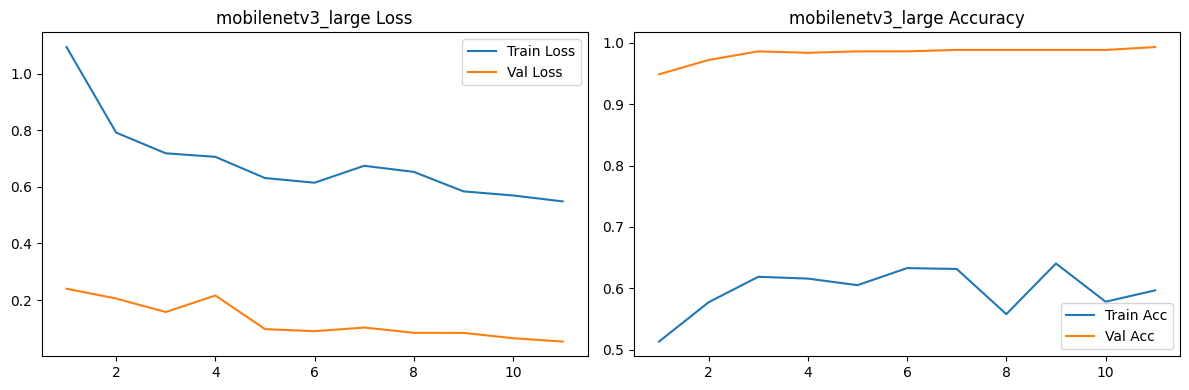


Training: resnext50_32x4d
Downloading: "https://download.pytorch.org/models/resnext50_32x4d-7cdf4587.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-7cdf4587.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 195MB/s]


Trainable params: 22,994,247
[resnext50_32x4d] Epoch 01/30 | train_loss=0.8447 train_acc=0.5449 | val_loss=0.1010 val_acc=0.9907 | best_val_loss=0.1010
[resnext50_32x4d] Epoch 02/30 | train_loss=0.6977 train_acc=0.5889 | val_loss=0.0698 val_acc=0.9930 | best_val_loss=0.0698
[resnext50_32x4d] Epoch 03/30 | train_loss=0.6488 train_acc=0.6544 | val_loss=0.0889 val_acc=0.9907 | best_val_loss=0.0698
[resnext50_32x4d] Epoch 04/30 | train_loss=0.6761 train_acc=0.6712 | val_loss=0.0748 val_acc=0.9953 | best_val_loss=0.0698
[resnext50_32x4d] Epoch 05/30 | train_loss=0.6446 train_acc=0.6249 | val_loss=0.0669 val_acc=0.9977 | best_val_loss=0.0669
[resnext50_32x4d] Epoch 06/30 | train_loss=0.6042 train_acc=0.6396 | val_loss=0.0416 val_acc=0.9953 | best_val_loss=0.0416
[resnext50_32x4d] Epoch 07/30 | train_loss=0.6084 train_acc=0.6727 | val_loss=0.0683 val_acc=0.9953 | best_val_loss=0.0416
[resnext50_32x4d] Epoch 08/30 | train_loss=0.5964 train_acc=0.6643 | val_loss=0.0695 val_acc=0.9953 | best_val

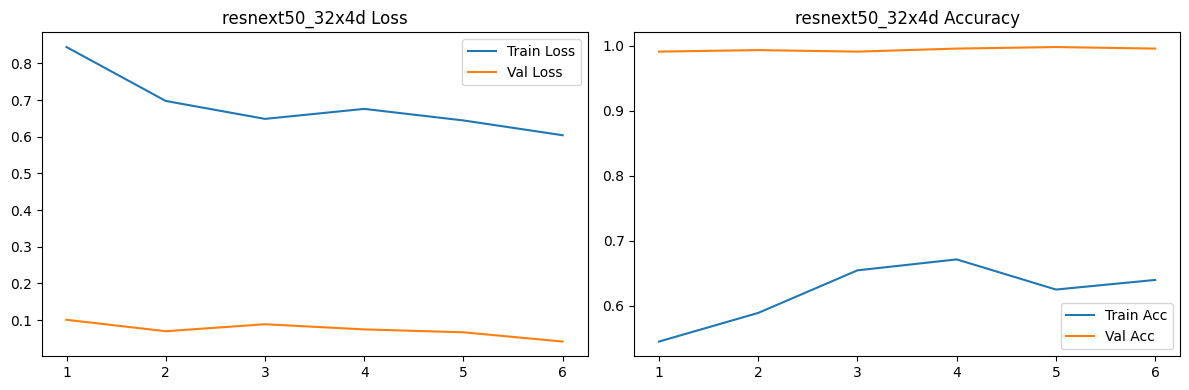


Training: efficientnet_b3
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 146MB/s]


Trainable params: 10,706,991
[efficientnet_b3] Epoch 01/30 | train_loss=1.3400 train_acc=0.4823 | val_loss=0.3068 val_acc=0.9673 | best_val_loss=0.3068
[efficientnet_b3] Epoch 02/30 | train_loss=0.7983 train_acc=0.5600 | val_loss=0.1743 val_acc=0.9907 | best_val_loss=0.1743
[efficientnet_b3] Epoch 03/30 | train_loss=0.7041 train_acc=0.5756 | val_loss=0.1011 val_acc=0.9953 | best_val_loss=0.1011
[efficientnet_b3] Epoch 04/30 | train_loss=0.6451 train_acc=0.6767 | val_loss=0.0538 val_acc=0.9977 | best_val_loss=0.0538
[efficientnet_b3] Epoch 05/30 | train_loss=0.6395 train_acc=0.6495 | val_loss=0.0515 val_acc=0.9953 | best_val_loss=0.0515
[efficientnet_b3] Epoch 06/30 | train_loss=0.6248 train_acc=0.6086 | val_loss=0.0656 val_acc=0.9907 | best_val_loss=0.0515
[efficientnet_b3] Epoch 07/30 | train_loss=0.5663 train_acc=0.6524 | val_loss=0.0431 val_acc=0.9977 | best_val_loss=0.0431
[efficientnet_b3] Epoch 08/30 | train_loss=0.5887 train_acc=0.6559 | val_loss=0.0473 val_acc=0.9977 | best_val

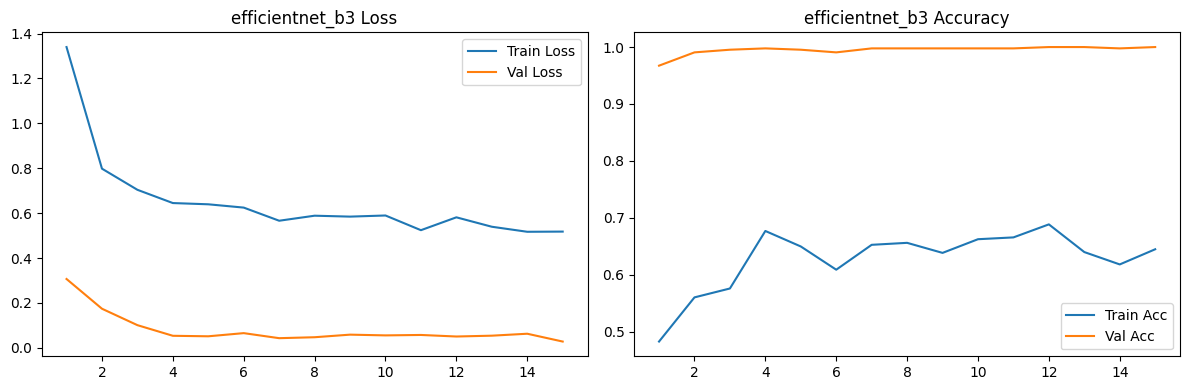

In [6]:
def build_mobilenetv3_large(num_classes):
    try:
        base = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1)
    except Exception:
        base = models.mobilenet_v3_large(pretrained=True)
    in_features = base.classifier[-1].in_features
    base.classifier[-1] = nn.Linear(in_features, num_classes)
    return base

def build_resnext50_32x4d(num_classes):
    try:
        base = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V1)
    except Exception:
        base = models.resnext50_32x4d(pretrained=True)
    in_features = base.fc.in_features
    base.fc = nn.Linear(in_features, num_classes)
    return base

def build_efficientnet_b3(num_classes):
    try:
        base = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
    except Exception:
        base = models.efficientnet_b3(pretrained=True)
    in_features = base.classifier[-1].in_features
    base.classifier[-1] = nn.Linear(in_features, num_classes)
    return base

MODEL_BUILDERS = {
    "mobilenetv3_large": build_mobilenetv3_large,
    "resnext50_32x4d": build_resnext50_32x4d,
    "efficientnet_b3": build_efficientnet_b3,
}

all_histories = {}
all_checkpoints = {}
all_models = {}

for model_key in CFG["model_order"]:
    print("\n" + "=" * 80)
    print("Training:", model_key)
    print("=" * 80)

    model = MODEL_BUILDERS[model_key](NUM_CLASSES).to(device)
    print("Trainable params:", f"{count_trainable_params(model):,}")

    trained_model, history, best_path = train_one_model(model, model_key, train_loader, val_loader)

    all_models[model_key] = trained_model
    all_histories[model_key] = history
    all_checkpoints[model_key] = best_path

    plot_history(history, model_key)
    torch.cuda.empty_cache()

# 7. Evaluation & Comparison

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,ms_per_batch,trainable_params
2,efficientnet_b3,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2418.744397,10706991
0,mobilenetv3_large,0.997722,0.998319,0.997449,0.997868,0.997749,0.997722,0.997719,2907.031693,4210999
1,resnext50_32x4d,0.993166,0.993537,0.993197,0.993281,0.993318,0.993166,0.993163,2914.419574,22994247


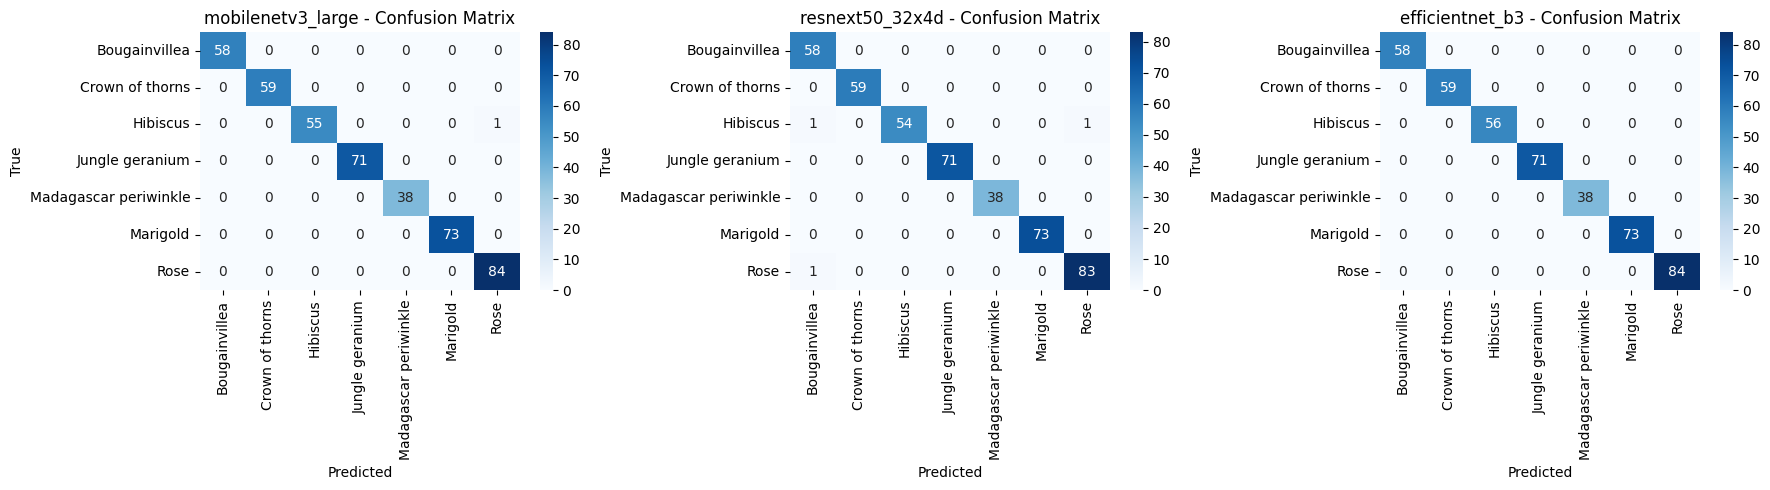


Classification report: mobilenetv3_large
                       precision    recall  f1-score   support

        Bougainvillea       1.00      1.00      1.00        58
      Crown of thorns       1.00      1.00      1.00        59
             Hibiscus       1.00      0.98      0.99        56
      Jungle geranium       1.00      1.00      1.00        71
Madagascar periwinkle       1.00      1.00      1.00        38
             Marigold       1.00      1.00      1.00        73
                 Rose       0.99      1.00      0.99        84

             accuracy                           1.00       439
            macro avg       1.00      1.00      1.00       439
         weighted avg       1.00      1.00      1.00       439


Classification report: resnext50_32x4d
                       precision    recall  f1-score   support

        Bougainvillea       0.97      1.00      0.98        58
      Crown of thorns       1.00      1.00      1.00        59
             Hibiscus       1.00

In [7]:
rows = []
pred_cache = {}

for model_key in CFG["model_order"]:
    model = MODEL_BUILDERS[model_key](NUM_CLASSES).to(device)
    ckpt = load_checkpoint(all_checkpoints[model_key], model)
    eval_stats = evaluate_loader(model, test_loader, criterion=nn.CrossEntropyLoss())

    y_true = eval_stats["y_true"]
    y_pred = eval_stats["y_pred"]

    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    rows.append({
        "model": model_key,
        "accuracy": acc,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted,
        "ms_per_batch": eval_stats["ms_per_batch"],
        "trainable_params": count_trainable_params(model)
    })

    pred_cache[model_key] = {
        "model": model,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": eval_stats["y_prob"],
        "cm": cm
    }

results_df = pd.DataFrame(rows).sort_values("f1_weighted", ascending=False)
display(results_df)

results_df.to_csv(Path(CFG["results_dir"]) / "model_comparison.csv", index=False)

# Confusion matrices
n_models = len(CFG["model_order"])
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))

if n_models == 1:
    axes = [axes]

for ax, model_key in zip(axes, CFG["model_order"]):
    cm = pred_cache[model_key]["cm"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{model_key} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig(Path(CFG["plots_dir"]) / "test_confusion_matrices.png", dpi=CFG["plot_dpi"])
plt.show()

# Optional: detailed report per model
for model_key in CFG["model_order"]:
    print("\n" + "=" * 80)
    print("Classification report:", model_key)
    print("=" * 80)
    print(classification_report(
        pred_cache[model_key]["y_true"],
        pred_cache[model_key]["y_pred"],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

# 8. Robustness Analysis

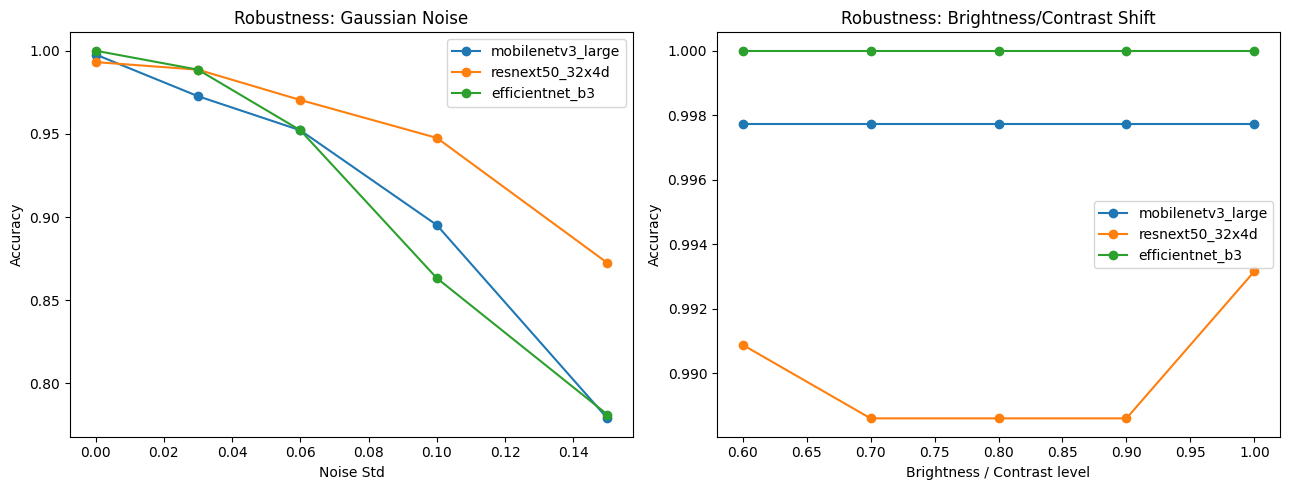

,model,shift,severity,accuracy,ms_per_batch
0,mobilenetv3_large,gaussian_noise,0.0,0.997722,2395.001501
1,mobilenetv3_large,gaussian_noise,0.03,0.972665,2576.903422
2,mobilenetv3_large,gaussian_noise,0.06,0.952164,2528.907129
3,mobilenetv3_large,gaussian_noise,0.1,0.895216,2658.153021
4,mobilenetv3_large,gaussian_noise,0.15,0.779043,2572.410947
5,mobilenetv3_large,brightness_contrast,1.00/1.00,0.997722,1918.502389
6,mobilenetv3_large,brightness_contrast,0.90/0.90,0.997722,1955.504170
7,mobilenetv3_large,brightness_contrast,0.80/0.80,0.997722,1939.016566
8,mobilenetv3_large,brightness_contrast,0.70/0.70,0.997722,1894.449870
9,mobilenetv3_large,brightness_contrast,0.60/0.60,0.997722,1906.294429


In [8]:
# Base loader for robustness: ToTensor only, then normalization happens inside evaluation
robust_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((CFG["img_size"] + CFG["resize_margin"], CFG["img_size"] + CFG["resize_margin"])),
    transforms.CenterCrop(CFG["img_size"]),
    transforms.ToTensor(),
])

robust_dataset = datasets.ImageFolder(CFG["test_dir"], transform=robust_tfms)
robust_loader = DataLoader(
    robust_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=CFG["pin_memory"]
)

mean = torch.tensor(CFG["imagenet_mean"]).view(1, 3, 1, 1)
std = torch.tensor(CFG["imagenet_std"]).view(1, 3, 1, 1)

def normalize_batch(x):
    return (x - mean.to(x.device)) / std.to(x.device)

def shift_gaussian_noise(x, noise_std):
    if noise_std <= 0:
        return x
    noise = torch.randn_like(x) * noise_std
    return torch.clamp(x + noise, 0.0, 1.0)

def shift_brightness_contrast(x, brightness=1.0, contrast=1.0):
    out = []
    for img in x:
        img = TF.adjust_brightness(img, brightness)
        img = TF.adjust_contrast(img, contrast)
        out.append(torch.clamp(img, 0.0, 1.0))
    return torch.stack(out, dim=0)

@torch.no_grad()
def evaluate_under_shift(model, loader, shift_fn=None):
    model.eval()
    y_true, y_pred = [], []
    start = time.perf_counter()

    for xb, yb in loader:
        xb = xb.float()
        if shift_fn is not None:
            xb = shift_fn(xb)

        xb = normalize_batch(xb).to(device)
        yb = yb.to(device)

        out = model(xb)
        if isinstance(out, (tuple, list)):
            out = out[0]

        preds = torch.argmax(out, dim=1)
        y_true.extend(yb.cpu().numpy().tolist())
        y_pred.extend(preds.cpu().numpy().tolist())

    elapsed = time.perf_counter() - start
    acc = accuracy_score(y_true, y_pred)
    return acc, (elapsed / max(len(loader), 1)) * 1000.0

# 1) Gaussian noise
noise_curves = defaultdict(list)
for model_key in CFG["model_order"]:
    model = MODEL_BUILDERS[model_key](NUM_CLASSES).to(device)
    load_checkpoint(all_checkpoints[model_key], model)

    for s in CFG["robust_noise_stds"]:
        acc, ms = evaluate_under_shift(model, robust_loader, shift_fn=lambda x, s=s: shift_gaussian_noise(x, s))
        noise_curves[model_key].append((s, acc, ms))

# 2) Brightness + contrast shift
bc_curves = defaultdict(list)
for model_key in CFG["model_order"]:
    model = MODEL_BUILDERS[model_key](NUM_CLASSES).to(device)
    load_checkpoint(all_checkpoints[model_key], model)

    for b, c in zip(CFG["robust_brightness_levels"], CFG["robust_contrast_levels"]):
        acc, ms = evaluate_under_shift(model, robust_loader, shift_fn=lambda x, b=b, c=c: shift_brightness_contrast(x, b, c))
        bc_curves[model_key].append((b, c, acc, ms))

# Plot degradation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_key in CFG["model_order"]:
    xs = [t[0] for t in noise_curves[model_key]]
    ys = [t[1] for t in noise_curves[model_key]]
    axes[0].plot(xs, ys, marker="o", label=model_key)

axes[0].set_title("Robustness: Gaussian Noise")
axes[0].set_xlabel("Noise Std")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

for model_key in CFG["model_order"]:
    xs = [t[0] for t in bc_curves[model_key]]
    ys = [t[2] for t in bc_curves[model_key]]
    axes[1].plot(xs, ys, marker="o", label=model_key)

axes[1].set_title("Robustness: Brightness/Contrast Shift")
axes[1].set_xlabel("Brightness / Contrast level")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(Path(CFG["plots_dir"]) / "robustness_curves.png", dpi=CFG["plot_dpi"])
plt.show()

robust_rows = []
for model_key in CFG["model_order"]:
    for s, acc, ms in noise_curves[model_key]:
        robust_rows.append({
            "model": model_key,
            "shift": "gaussian_noise",
            "severity": s,
            "accuracy": acc,
            "ms_per_batch": ms
        })
    for b, c, acc, ms in bc_curves[model_key]:
        robust_rows.append({
            "model": model_key,
            "shift": "brightness_contrast",
            "severity": f"{b:.2f}/{c:.2f}",
            "accuracy": acc,
            "ms_per_batch": ms
        })

robust_df = pd.DataFrame(robust_rows)
display(robust_df.head(10))
robust_df.to_csv(Path(CFG["results_dir"]) / "robustness_results.csv", index=False)

# 9. Error Analysis

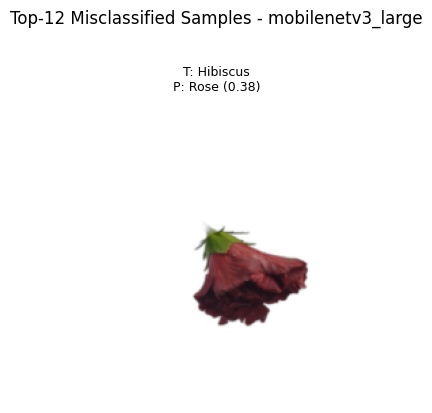


Most common confusion pairs for mobilenetv3_large
Hibiscus -> Rose: 1


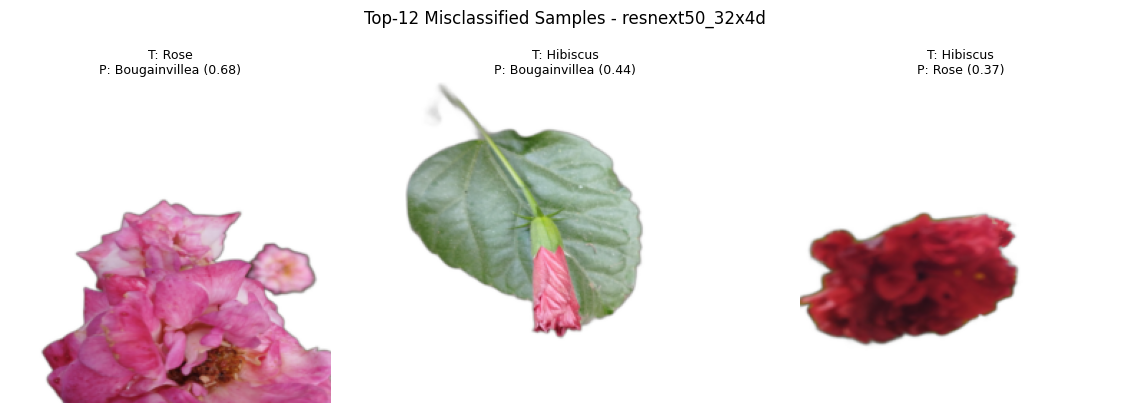


Most common confusion pairs for resnext50_32x4d
Rose -> Bougainvillea: 1
Hibiscus -> Bougainvillea: 1
Hibiscus -> Rose: 1
No misclassifications found for Top-12 Misclassified Samples - efficientnet_b3

Most common confusion pairs for efficientnet_b3


In [9]:
class ImageFolderWithPaths(datasets.ImageFolder):
    def __getitem__(self, index):
        img, target = super().__getitem__(index)
        path = self.samples[index][0]
        return img, target, path

vis_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((CFG["img_size"] + CFG["resize_margin"], CFG["img_size"] + CFG["resize_margin"])),
    transforms.CenterCrop(CFG["img_size"]),
    transforms.ToTensor(),
])

error_dataset = ImageFolderWithPaths(CFG["test_dir"], transform=vis_tfms)
error_loader = DataLoader(
    error_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=CFG["pin_memory"]
)

@torch.no_grad()
def collect_top_misclassified(model, loader, top_k=12):
    model.eval()
    records = []

    for xb, yb, paths in loader:
        xb = xb.float()
        xb_norm = normalize_batch(xb).to(device)
        yb = yb.to(device)

        out = model(xb_norm)
        if isinstance(out, (tuple, list)):
            out = out[0]

        probs = torch.softmax(out, dim=1)
        pred = probs.argmax(dim=1)
        conf = probs.max(dim=1).values

        for i in range(xb.size(0)):
            if pred[i] != yb[i]:
                records.append({
                    "image": xb[i].cpu(),
                    "true": int(yb[i].cpu().item()),
                    "pred": int(pred[i].cpu().item()),
                    "conf": float(conf[i].cpu().item()),
                    "path": paths[i]
                })

    records = sorted(records, key=lambda r: r["conf"], reverse=True)
    return records[:top_k]

def show_error_grid(records, title, class_names):
    if not records:
        print(f"No misclassifications found for {title}")
        return

    n = len(records)
    cols = min(4, n)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes[n:]:
        ax.axis("off")

    for ax, rec in zip(axes, records):
        img = rec["image"].permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)

        ax.imshow(img)
        ax.axis("off")
        true_name = class_names[rec["true"]]
        pred_name = class_names[rec["pred"]]
        ax.set_title(f"T: {true_name}\nP: {pred_name} ({rec['conf']:.2f})", fontsize=9)

    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

for model_key in CFG["model_order"]:
    model = MODEL_BUILDERS[model_key](NUM_CLASSES).to(device)
    load_checkpoint(all_checkpoints[model_key], model)

    top_errors = collect_top_misclassified(model, error_loader, top_k=CFG["top_k_errors"])
    show_error_grid(top_errors, f"Top-{CFG['top_k_errors']} Misclassified Samples - {model_key}", CLASS_NAMES)

    # Print the most common confusion pairs
    pair_counter = Counter((CLASS_NAMES[r["true"]], CLASS_NAMES[r["pred"]]) for r in top_errors)
    print("\nMost common confusion pairs for", model_key)
    for (t, p), c in pair_counter.most_common():
        print(f"{t} -> {p}: {c}")